<a href="https://colab.research.google.com/github/tougheye/geo_mapping/blob/main/UPTE_Assembly_Dist_Mapping.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This project is to map the distribution of UPTE bargaining unit membership across all state assembly districts

In [ ]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

ca_assembly_shape_df = gpd.read_file("/content/CA_State_Assembly_Districts_and_Membership_2024_to_2026.zip")
ca_assembly_shape_df.head()

,FID,DISTRICT,MEMBERS,NAME,LAST_NAME,PARTY,POPULATION,WEBSITE,PHOTO,CONT_URL,CAP_OFFICE,MAIL_ADD,DIST_ADD,COUNT_REP,MEM_SUMM,geometry
0,1,1,1,Heather,Hadwick,Republican,506402,https://ad01.asmrc.org/,https://www.assembly.ca.gov/sites/assembly.ca....,https://lcmspubcontact.lc.ca.gov/PublicLCMS/Co...,"Capitol Office, 1021 O Street, Suite 5710, Sac...","P.O. Box 942849, Sacramento, CA 94249-0001; (9...","113 Presley Way, Suite 10, Grass Valley, CA 95...","alpine, amador, el dorado, lassen, modoc, neva...",https://www.assembly.ca.gov/assemblymembers/01,"POLYGON ((-120.15191 41.99463, -120.15118 41.9..."
1,2,10,1,Stephanie,Nguyen,Democrat,518416,https://a10.asmdc.org/,https://www.assembly.ca.gov/sites/assembly.ca....,https://lcmspubcontact.lc.ca.gov/PublicLCMS/Co...,"Capitol Office, 1021 O Street, Suite 5720, Sac...","P.O. Box 942849, Sacramento, CA 94249-0010; (9...","9250 Laguna Springs Drive, Suite 220, Elk Grov...",sacramento,https://www.assembly.ca.gov/assemblymembers/10,"POLYGON ((-121.39074 38.53966, -121.39082 38.5..."
2,3,11,1,Lori,Wilson,Democrat,514921,https://a11.asmdc.org/,https://www.assembly.ca.gov/sites/assembly.ca....,https://lcmspubcontact.lc.ca.gov/PublicLCMS/Co...,"Capitol Office, 1021 O Street, Suite 8110, Sac...","P.O. Box 942849, Sacramento, CA 94249-0011; (9...","One Harbor Center, Suite 270, Suisun City, CA ...","contra costa, sacramento, solano",https://www.assembly.ca.gov/assemblymembers/11,"POLYGON ((-121.6678 37.87854, -121.66829 37.87..."
3,4,12,1,Damon,Connolly,Democrat,482778,https://a12.asmdc.org/,https://www.assembly.ca.gov/sites/assembly.ca....,https://lcmspubcontact.lc.ca.gov/PublicLCMS/Co...,"Capitol Office, 1021 O Street, Suite 5240, Sac...","P.O. Box 942849, Sacramento, CA 94249-0012; (9...","3501 Civic Center Drive, Room 412, San Rafael,...","marin, sonoma",https://www.assembly.ca.gov/assemblymembers/12,"POLYGON ((-122.61229 37.81522, -122.62609 37.8..."
4,5,13,1,Rhodesia,Ransom,Democrat,489925,https://a13.asmdc.org/,https://www.assembly.ca.gov/sites/assembly.ca....,https://lcmspubcontact.lc.ca.gov/PublicLCMS/Co...,"Capitol Office, 1021 O Street, Suite 6340, Sac...","P.O. Box 942849, Sacramento, CA 94249-0013; (9...","4643 Quail Lakes Drive, Suite 200, Stockton, C...",san joaquin,https://www.assembly.ca.gov/assemblymembers/13,"POLYGON ((-121.55666 37.55004, -121.55666 37.5..."


In [ ]:
ca_assembly_shape_df.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   FID         80 non-null     int32   
 1   DISTRICT    80 non-null     int64   
 2   MEMBERS     80 non-null     int32   
 3   NAME        80 non-null     object  
 4   LAST_NAME   80 non-null     object  
 5   PARTY       80 non-null     object  
 6   POPULATION  80 non-null     int32   
 7   WEBSITE     80 non-null     object  
 8   PHOTO       80 non-null     object  
 9   CONT_URL    80 non-null     object  
 10  CAP_OFFICE  80 non-null     object  
 11  MAIL_ADD    80 non-null     object  
 12  DIST_ADD    80 non-null     object  
 13  COUNT_REP   80 non-null     object  
 14  MEM_SUMM    80 non-null     object  
 15  geometry    80 non-null     geometry
dtypes: geometry(1), int32(3), int64(1), object(11)
memory usage: 9.2+ KB


In [ ]:
ca_assembly_shape_df['DISTRICT'] = ca_assembly_shape_df['DISTRICT'].astype(int)

In [ ]:
upte_assembly_cnt_df = pd.read_csv("/content/UPTE_CA_Assembly_Summary.csv")
upte_assembly_cnt_df.head()

,CA Assembly District,UPTE Headcout
0,1,46
1,2,56
2,3,72
3,4,962
4,5,356


In [ ]:
upte_assembly_cnt_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 2 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   CA Assembly District  80 non-null     int64
 1   UPTE Headcout         80 non-null     int64
dtypes: int64(2)
memory usage: 1.4 KB


In [ ]:
ca_asmbl_dist_to_map = ca_assembly_shape_df.merge(upte_assembly_cnt_df, left_on='DISTRICT', right_on='CA Assembly District')
#

In [ ]:
ca_asmbl_dist_to_map.head()

,FID,DISTRICT,MEMBERS,NAME,LAST_NAME,PARTY,POPULATION,WEBSITE,PHOTO,CONT_URL,CAP_OFFICE,MAIL_ADD,DIST_ADD,COUNT_REP,MEM_SUMM,geometry,CA Assembly District,UPTE Headcout
0,1,1,1,Heather,Hadwick,Republican,506402,https://ad01.asmrc.org/,https://www.assembly.ca.gov/sites/assembly.ca....,https://lcmspubcontact.lc.ca.gov/PublicLCMS/Co...,"Capitol Office, 1021 O Street, Suite 5710, Sac...","P.O. Box 942849, Sacramento, CA 94249-0001; (9...","113 Presley Way, Suite 10, Grass Valley, CA 95...","alpine, amador, el dorado, lassen, modoc, neva...",https://www.assembly.ca.gov/assemblymembers/01,"POLYGON ((-120.15191 41.99463, -120.15118 41.9...",1,46
1,2,10,1,Stephanie,Nguyen,Democrat,518416,https://a10.asmdc.org/,https://www.assembly.ca.gov/sites/assembly.ca....,https://lcmspubcontact.lc.ca.gov/PublicLCMS/Co...,"Capitol Office, 1021 O Street, Suite 5720, Sac...","P.O. Box 942849, Sacramento, CA 94249-0010; (9...","9250 Laguna Springs Drive, Suite 220, Elk Grov...",sacramento,https://www.assembly.ca.gov/assemblymembers/10,"POLYGON ((-121.39074 38.53966, -121.39082 38.5...",10,625
2,3,11,1,Lori,Wilson,Democrat,514921,https://a11.asmdc.org/,https://www.assembly.ca.gov/sites/assembly.ca....,https://lcmspubcontact.lc.ca.gov/PublicLCMS/Co...,"Capitol Office, 1021 O Street, Suite 8110, Sac...","P.O. Box 942849, Sacramento, CA 94249-0011; (9...","One Harbor Center, Suite 270, Suisun City, CA ...","contra costa, sacramento, solano",https://www.assembly.ca.gov/assemblymembers/11,"POLYGON ((-121.6678 37.87854, -121.66829 37.87...",11,342
3,4,12,1,Damon,Connolly,Democrat,482778,https://a12.asmdc.org/,https://www.assembly.ca.gov/sites/assembly.ca....,https://lcmspubcontact.lc.ca.gov/PublicLCMS/Co...,"Capitol Office, 1021 O Street, Suite 5240, Sac...","P.O. Box 942849, Sacramento, CA 94249-0012; (9...","3501 Civic Center Drive, Room 412, San Rafael,...","marin, sonoma",https://www.assembly.ca.gov/assemblymembers/12,"POLYGON ((-122.61229 37.81522, -122.62609 37.8...",12,198
4,5,13,1,Rhodesia,Ransom,Democrat,489925,https://a13.asmdc.org/,https://www.assembly.ca.gov/sites/assembly.ca....,https://lcmspubcontact.lc.ca.gov/PublicLCMS/Co...,"Capitol Office, 1021 O Street, Suite 6340, Sac...","P.O. Box 942849, Sacramento, CA 94249-0013; (9...","4643 Quail Lakes Drive, Suite 200, Stockton, C...",san joaquin,https://www.assembly.ca.gov/assemblymembers/13,"POLYGON ((-121.55666 37.55004, -121.55666 37.5...",13,70


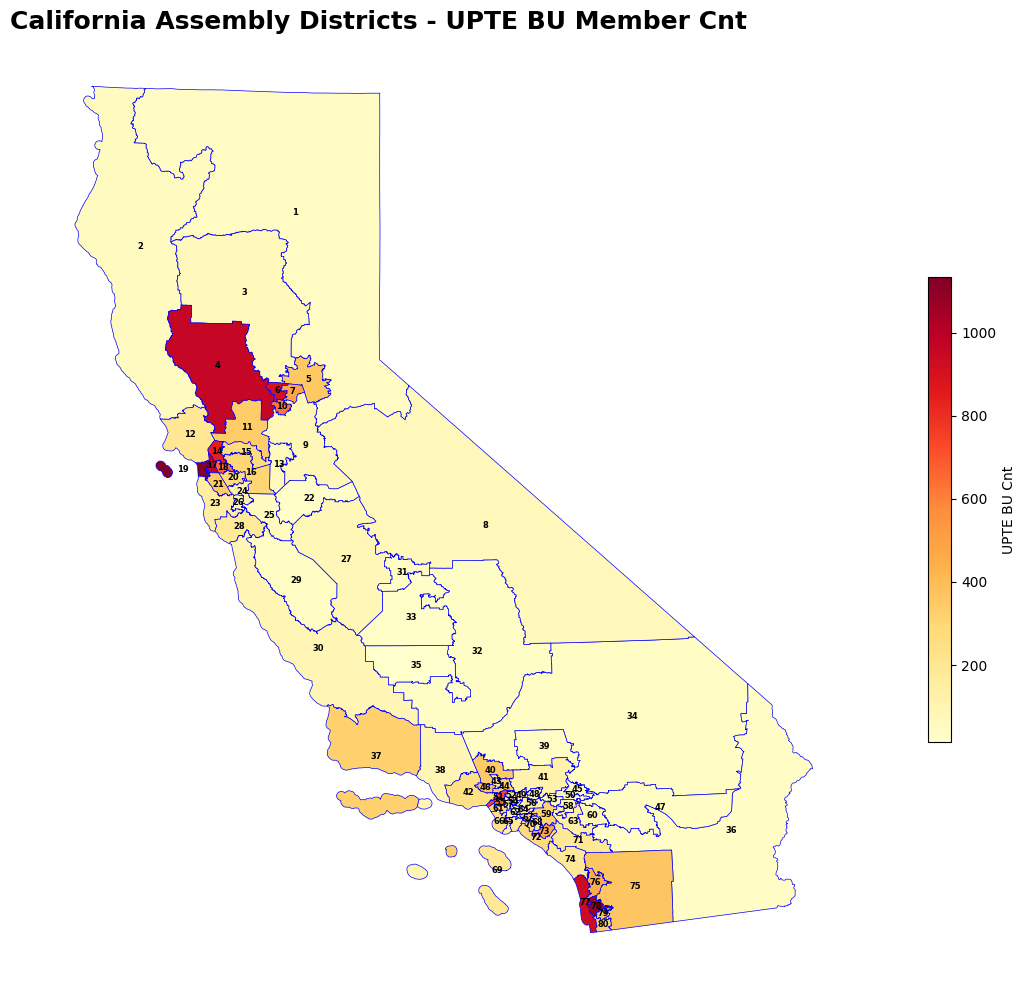

In [ ]:
ca_asmbl_dist_to_map = ca_asmbl_dist_to_map.to_crs("EPSG:3310")

# create a California specific figure
fig_ca, ax_ca = plt.subplots(figsize=(16, 10))

# setup the color scale
col = 'UPTE Headcout'
vmin = ca_asmbl_dist_to_map[col].min()
vmax = ca_asmbl_dist_to_map[col].max()
cmap = 'YlOrRd'


# ── Plot California members ──────────────────────────────────────────────────────────
ca_asmbl_dist_to_map.plot(ax=ax_ca, column=col, cmap=cmap, vmin=vmin, vmax=vmax,
              edgecolor='blue', linewidth=0.5, legend=True,
           legend_kwds={'label': 'UPTE BU Cnt', 'shrink': 0.5})

# Labels for CA — centroid-based
for _, row in ca_asmbl_dist_to_map.iterrows():
    centroid = row.geometry.centroid
    ax_ca.annotate(
        text=row['DISTRICT'],
        xy=(centroid.x, centroid.y),
        ha='center', va='center',
        fontsize=6, color='black',
        fontweight='bold',
        clip_on=True
    )

ax_ca.set_axis_off()

plt.suptitle('California Assembly Districts - UPTE BU Member Cnt',
             fontsize=18, fontweight='bold')
plt.tight_layout()
plt.savefig('upte_ca_map.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# create regional distinctions
regional_dict = {"Northern and Sierra": [1, 2, 3, 8],
                 "SF Bay and Greater Sacramento": [4, 6, 7, 5, 10, 11, 12, 15, 14, 16, 17,
                                                   18, 19, 20, 21, 23, 24, 25, 26],
                 "Central Valley and High Desert": [27, 9, 13, 22, 31, 32, 33, 34, 35, 39, 47, 36],
                 "Central Coast": [ 28, 29, 30, 37, 38],
                 "SoCal - Greater LA, OC, IE": [40, 41, 42, 43, 44, 45, 46, 48, 49, 50,
                                                51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61,
                                                62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73],
                 "SoCal - Greater SD": [ 74, 75, 76, 77, 78, 79, 80]}

In [ ]:
import pandas as pd
ca_asmbl_reg_df = pd.Series(regional_dict).explode().reset_index()
ca_asmbl_reg_df.columns = [ 'Region' , 'Assembly District']
ca_asmbl_reg_df.head()

,Region,Assembly District
0,Northern and Sierra,1
1,Northern and Sierra,2
2,Northern and Sierra,3
3,Northern and Sierra,8
4,SF Bay and Greater Sacramento,4


In [ ]:
ca_dist_map_w_region = ca_asmbl_dist_to_map.merge(ca_asmbl_reg_df, left_on='DISTRICT', right_on='Assembly District')
#

In [ ]:
ca_dist_map_w_region.head()

,FID,DISTRICT,MEMBERS,NAME,LAST_NAME,PARTY,POPULATION,WEBSITE,PHOTO,CONT_URL,CAP_OFFICE,MAIL_ADD,DIST_ADD,COUNT_REP,MEM_SUMM,geometry,CA Assembly District,UPTE Headcout,Region,Assembly District
0,1,1,1,Heather,Hadwick,Republican,506402,https://ad01.asmrc.org/,https://www.assembly.ca.gov/sites/assembly.ca....,https://lcmspubcontact.lc.ca.gov/PublicLCMS/Co...,"Capitol Office, 1021 O Street, Suite 5710, Sac...","P.O. Box 942849, Sacramento, CA 94249-0001; (9...","113 Presley Way, Suite 10, Grass Valley, CA 95...","alpine, amador, el dorado, lassen, modoc, neva...",https://www.assembly.ca.gov/assemblymembers/01,"POLYGON ((-12611.506 441843.786, -12550.321 44...",1,46,Northern and Sierra,1
1,2,10,1,Stephanie,Nguyen,Democrat,518416,https://a10.asmdc.org/,https://www.assembly.ca.gov/sites/assembly.ca....,https://lcmspubcontact.lc.ca.gov/PublicLCMS/Co...,"Capitol Office, 1021 O Street, Suite 5720, Sac...","P.O. Box 942849, Sacramento, CA 94249-0010; (9...","9250 Laguna Springs Drive, Suite 220, Elk Grov...",sacramento,https://www.assembly.ca.gov/assemblymembers/10,"POLYGON ((-121080.329 59059.782, -121083.31 59...",10,625,SF Bay and Greater Sacramento,10
2,3,11,1,Lori,Wilson,Democrat,514921,https://a11.asmdc.org/,https://www.assembly.ca.gov/sites/assembly.ca....,https://lcmspubcontact.lc.ca.gov/PublicLCMS/Co...,"Capitol Office, 1021 O Street, Suite 8110, Sac...","P.O. Box 942849, Sacramento, CA 94249-0011; (9...","One Harbor Center, Suite 270, Suisun City, CA ...","contra costa, sacramento, solano",https://www.assembly.ca.gov/assemblymembers/11,"POLYGON ((-146492.94 -14032.641, -146535.249 -...",11,342,SF Bay and Greater Sacramento,11
3,4,12,1,Damon,Connolly,Democrat,482778,https://a12.asmdc.org/,https://www.assembly.ca.gov/sites/assembly.ca....,https://lcmspubcontact.lc.ca.gov/PublicLCMS/Co...,"Capitol Office, 1021 O Street, Suite 5240, Sac...","P.O. Box 942849, Sacramento, CA 94249-0012; (9...","3501 Civic Center Drive, Room 412, San Rafael,...","marin, sonoma",https://www.assembly.ca.gov/assemblymembers/12,"POLYGON ((-229629.073 -19196.546, -230822.612 ...",12,198,SF Bay and Greater Sacramento,12
4,5,13,1,Rhodesia,Ransom,Democrat,489925,https://a13.asmdc.org/,https://www.assembly.ca.gov/sites/assembly.ca....,https://lcmspubcontact.lc.ca.gov/PublicLCMS/Co...,"Capitol Office, 1021 O Street, Suite 6340, Sac...","P.O. Box 942849, Sacramento, CA 94249-0013; (9...","4643 Quail Lakes Drive, Suite 200, Stockton, C...",san joaquin,https://www.assembly.ca.gov/assemblymembers/13,"POLYGON ((-137330.732 -50712.765, -137330.677 ...",13,70,Central Valley and High Desert,13


In [ ]:
region_list = ca_dist_map_w_region['Region'].unique()


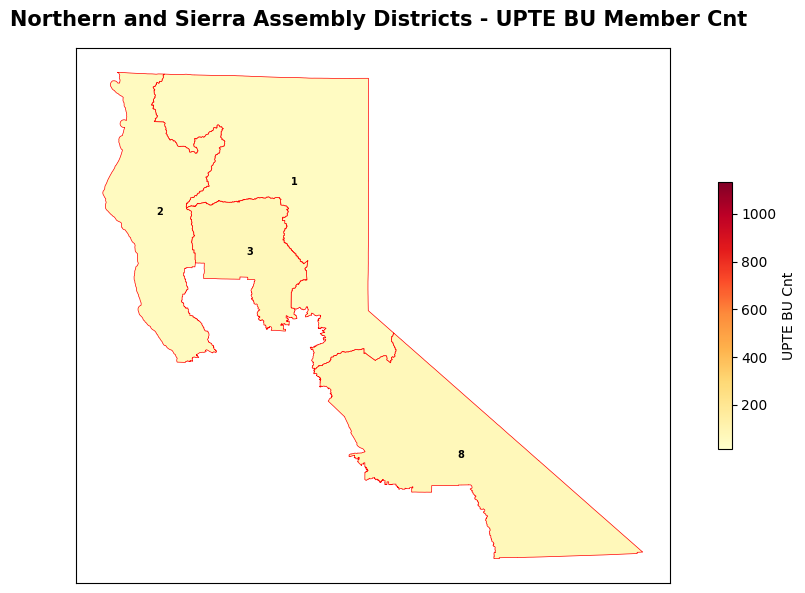

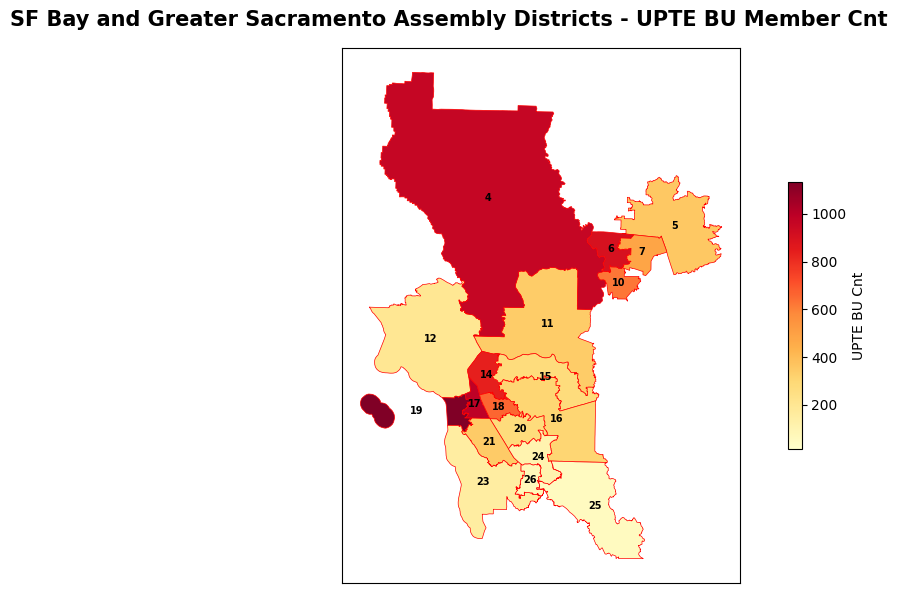

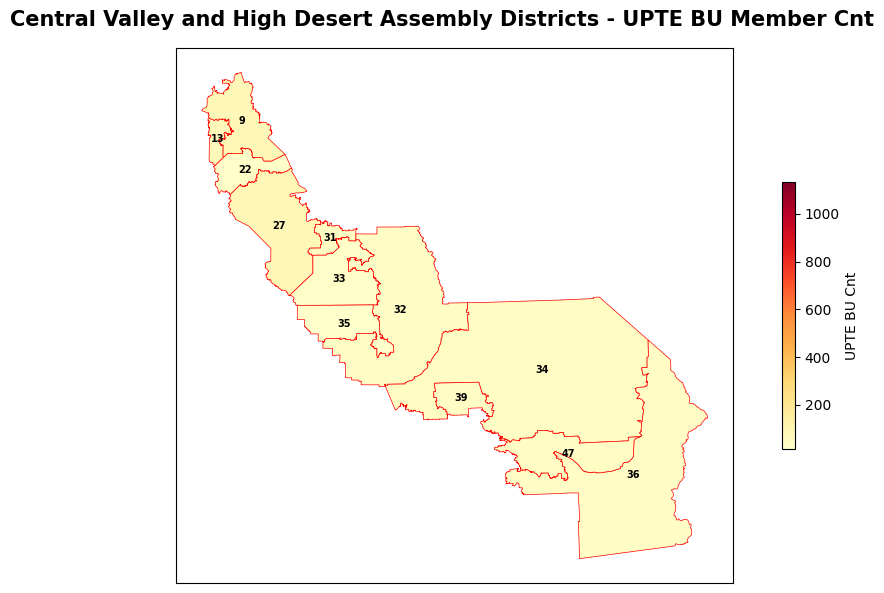

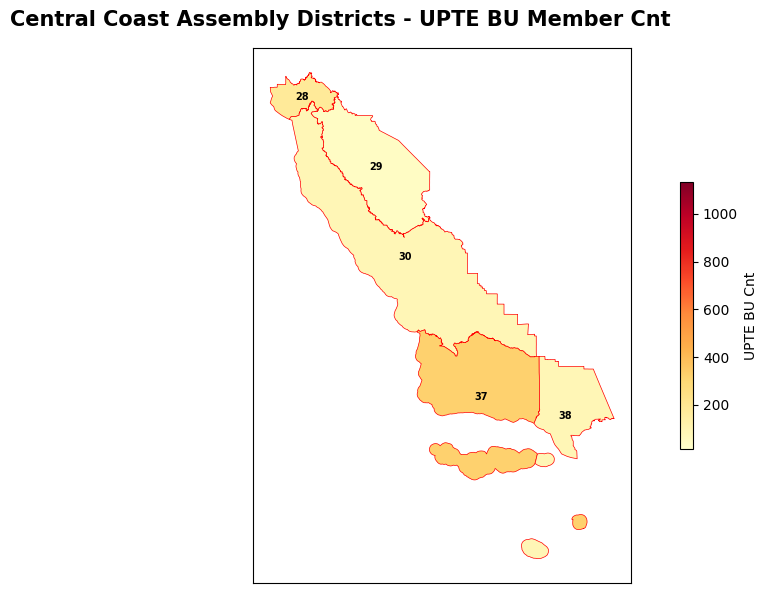

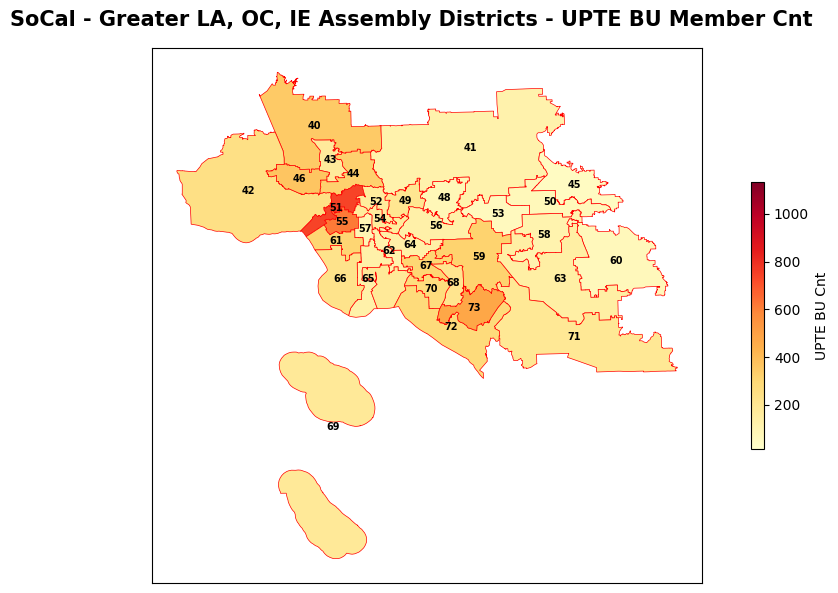

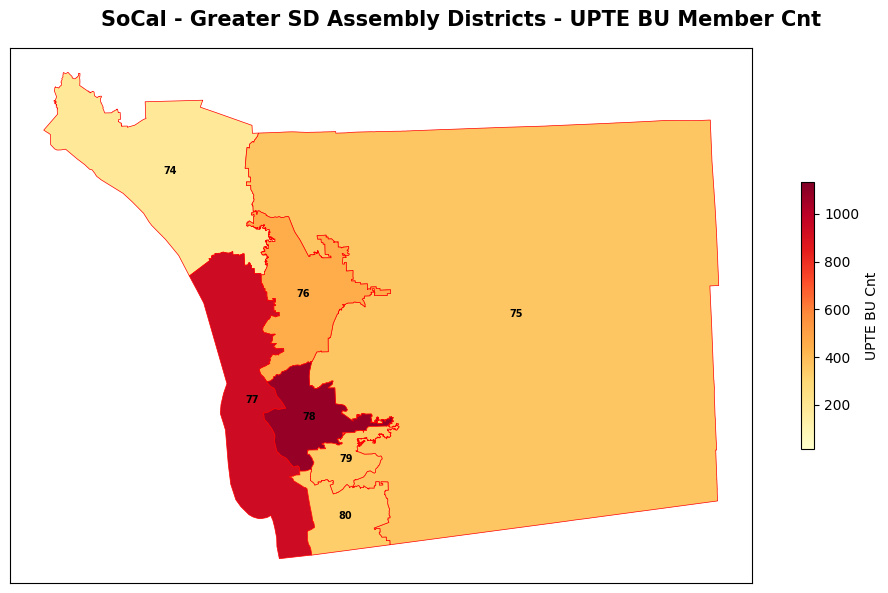

In [ ]:
for region in region_list:
  region_df = ca_dist_map_w_region[ca_dist_map_w_region['Region'] == region]

  # reproject to regional Albers
  region_df = region_df.to_crs("EPSG:3310")

  # create a region specific figure
  fig_region, ax_region = plt.subplots(figsize=(10, 6))

  # setup the color scale
  col = 'UPTE Headcout'
  vmin = ca_dist_map_w_region[col].min()
  vmax = ca_dist_map_w_region[col].max()
  cmap = 'YlOrRd'


  # ── Plot region's members ──────────────────────────────────────────────────────────
  region_df.plot(ax=ax_region, column=col, cmap=cmap, vmin=vmin, vmax=vmax,
                edgecolor='red', linewidth=0.5, legend=True,
            legend_kwds={'label': 'UPTE BU Cnt', 'shrink': 0.5})

  # Labels for regions — centroid-based
  for _, row in region_df.iterrows():
      centroid = row.geometry.centroid
      ax_region.annotate(
          text=row['Assembly District'],
          xy=(centroid.x, centroid.y),
          ha='center', va='center',
          fontsize=7, color='black',
          fontweight='bold',
          clip_on=True
      )

  ax_region.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

  plt.suptitle(f'{region} Assembly Districts - UPTE BU Member Cnt',
              fontsize=15, fontweight='bold')
  plt.tight_layout()
  plt.savefig(f'{region}_upte_ca_map.png', dpi=150, bbox_inches='tight')
  plt.show()

# print("Done printing all inset maps")